<!-- repro-header -->
> **Reproducibility header**
>
> - **Aim:** Tissue morphology and composition metrics per dataset vs. uRNA proportion.
> - **Manuscript panels:** ED Fig. 1B
> - **Inputs:** `data_with_source_score.zarr` (or `data_with_source_score_morphology.zarr` from `morphology/compute_missing_morphology.py` for CosMx/MERSCOPE) + notebook 11 output
> - **Outputs:** Morphology heatmap and correlations
> - **Environment / kernel:** `troutpy_drvi`
> - Data root: `/lustre/groups/ml01/datasets/projects/2025_sergio_troutpy` (ROIs on Zenodo 10.5281/zenodo.17446348). 


# 13. Morphology & tissue-composition complexity vs. uRNA (reviewer point 2)

Reviewer ask: extend Figure 1A with per-dataset **cell morphology complexity** (solidity,
circularity, etc.) and **cell type composition complexity after annotation**, and analyze
**how uRNA is associated with cell morphology indicators**.

`troutpy.pp.add_morphological_metrics` has already been run across most dataset/segmentation
combinations in the project (writes `area, perimeter, solidity, major_axis_length,
equivalent_diameter, circularity, protrusion_length, morphological_complexity` into
`sdata.tables["table"].obs`). This notebook is read-only: it scans the existing zarr stores,
builds a per-dataset summary, and merges it with the uRNA composition table produced by
[11_full_rna_classification.ipynb](11_full_rna_classification.ipynb).

True biological cell-type annotation exists for only 2/~19 datasets
(`xenium_msbrain_5k`, `atera_hsbreast`); for composition-complexity here we use unsupervised
Leiden-cluster diversity as an explicit proxy for the rest. A cell-type-resolved deep dive
(using real annotation) is done separately for `xenium_msbrain_5k` only, in
`notebooks/4_detailed_analysis/5_computing_cell_scores_msbrain.ipynb`.

## Setup

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import spatialdata as sd
from scipy.stats import entropy, spearmanr
from statsmodels.stats.multitest import multipletests
from scipy.spatial import ConvexHull
from sklearn.neighbors import NearestNeighbors

matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42
sns.set_style("whitegrid")

base_dir = "/lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/rois/"
saving_path = os.path.join(base_dir, "figures", "morphology_urna_association")
os.makedirs(saving_path, exist_ok=True)

segmentations = ["rois", "rois_proseg", "rois_segger"]  # same list/order as notebook 11
segmentation_labels = {"rois": "Default", "rois_proseg": "ProSeg", "rois_segger": "Segger"}

morphology_cols = [
    "area", "perimeter", "solidity", "major_axis_length", "equivalent_diameter",
    "circularity", "protrusion_length", "morphological_complexity",
]

/home/icb/sergio.salas/miniconda3/envs/troutpy_drvi/lib/python3.10/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(


/home/icb/sergio.salas/miniconda3/envs/troutpy_drvi/lib/python3.10/site-packages/xarray_schema/__init__.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFound, get_distribution


## Per-dataset zarr scan

Mirrors notebook 11 cell 8's scan loop, but reads `sdata.tables["table"].obs`
(tables only, no points/images) instead of the transcripts layer.

Some CosMx/MERSCOPE datasets have no populated raster labels layer in their default
pipeline output (their native segmentation is stored as polygon boundaries, never rasterized) --
for those, `data_with_source_score.zarr` has no morphology columns. Morphology for those was
computed separately by rasterizing `sdata.shapes["shapes"]` and running the same
regionprops-derived metrics (see `compute_missing_morphology.py`; validated against CosMx's own
native `Area` column, Spearman r=0.99+), written to a sibling `data_with_source_score_morphology.zarr`.
The scan below falls back to that file's morphology columns when the primary file is missing them.

### Tissue-intrinsic spatial-structure metrics

Beyond per-cell morphology and Leiden-composition diversity, three additional per-dataset
metrics are computed directly from cell centroids (`sdata.tables["table"].obsm["spatial"]`,
the physical "global" coordinate system spatialdata aligns all modalities to):

- **`cell_density`** — cells / convex-hull area of all cell centroids (a simple tissue-packing
  proxy). Sanity-checked (`inspect_spatial2.py`) to fall within one order of magnitude
  (~1.2k-9.5k cells/mm²) across Xenium, CosMx, MERSCOPE and Atera, so it is comparable across
  technologies without a per-platform unit correction.
- **`clark_evans_index`** — Clark & Evans (1954) nearest-neighbor aggregation index: mean
  observed nearest-neighbor distance divided by the distance expected under complete spatial
  randomness (CSR) at the same density (`0.5 / sqrt(density)`). <1 = cells are spatially
  clustered/aggregated, ≈1 = random (Poisson-like) arrangement, >1 = regularly spaced (e.g.
  epithelial packing). This is independent of density itself — two tissues can have the same
  density but very different packing regularity.
- **`leiden_heterotypic_neighbor_frac`** / **`leiden_mixing_index`** — how spatially
  *intermingled* Leiden clusters are, as opposed to how many there are (already captured by
  `leiden_shannon`/`evenness`/`simpson`). For each cell, the fraction of its k=10 nearest
  spatial neighbors carrying a *different* Leiden label is averaged over all cells
  (`leiden_heterotypic_neighbor_frac`). This is compared against the fraction expected if
  labels were randomly shuffled in space given the same cluster-size proportions — which is
  exactly the Simpson index (`leiden_simpson` = 1 − Σpᵢ²) — giving
  `leiden_mixing_index = observed / expected`. Values near 1 indicate well-mixed, salt-and-pepper
  arrangements; values well below 1 indicate spatially segregated domains (e.g. distinct tissue
  layers or niches) even when overall compositional diversity is high.


In [2]:
def load_cell_table(seg, sample):
    """Read sdata.tables['table'] (obs + spatial obsm) for one (segmentation, sample).
    Returns (obs, spatial, error)."""
    zarr_path = os.path.join(base_dir, seg, sample, "data_with_source_score.zarr")
    if not os.path.isdir(zarr_path):
        return None, None, "no data_with_source_score.zarr"
    try:
        sdata_local = sd.read_zarr(zarr_path, selection=("tables",))
        adata = sdata_local.tables["table"]
        obs = adata.obs.copy()
        spatial = adata.obsm["spatial"] if "spatial" in adata.obsm else None
    except Exception as e:
        return None, None, f"load failed: {type(e).__name__}: {e}"

    if not all(c in obs.columns for c in morphology_cols):
        alt_path = os.path.join(base_dir, seg, sample, "data_with_source_score_morphology.zarr")
        if os.path.isdir(alt_path):
            try:
                alt_sdata = sd.read_zarr(alt_path, selection=("tables",))
                alt_obs = alt_sdata.tables["table"].obs
                if all(c in alt_obs.columns for c in morphology_cols):
                    for c in morphology_cols:
                        obs[c] = alt_obs.reindex(obs.index)[c]
            except Exception:
                pass  # fallback failed silently; has_morphology stays False downstream

    return obs, spatial, None

In [3]:
records = []
skip_log = []

for seg in segmentations:
    root_dir = os.path.join(base_dir, seg)
    if not os.path.isdir(root_dir):
        continue
    subfolders = sorted(f.name for f in os.scandir(root_dir) if f.is_dir())
    for sample in subfolders:
        obs, spatial, err = load_cell_table(seg, sample)
        if obs is None:
            skip_log.append({"segmentation": seg, "sample": sample, "reason": err})
            continue

        rec = {"segmentation": seg, "sample": sample, "n_cells": len(obs)}

        has_morph = all(c in obs.columns for c in morphology_cols)
        rec["has_morphology"] = has_morph
        for c in morphology_cols:
            if has_morph:
                # Guard against degenerate single-pixel regions (perimeter=0 -> circularity=inf
                # from regionprops), which would otherwise poison the whole-dataset mean.
                vals = obs[c].replace([np.inf, -np.inf], np.nan)
                rec[f"{c}_mean"] = vals.mean()
                rec[f"{c}_median"] = vals.median()
                rec[f"{c}_n_nonfinite_dropped"] = int(obs[c].isin([np.inf, -np.inf]).sum())
            else:
                rec[f"{c}_mean"] = np.nan
                rec[f"{c}_median"] = np.nan
                rec[f"{c}_n_nonfinite_dropped"] = np.nan

        has_leiden = "leiden" in obs.columns
        rec["has_leiden"] = has_leiden
        if has_leiden:
            props = obs["leiden"].value_counts(normalize=True)
            n_clusters = len(props)
            rec["n_leiden_clusters"] = n_clusters
            rec["leiden_shannon"] = entropy(props, base=2)
            rec["leiden_evenness"] = rec["leiden_shannon"] / np.log2(n_clusters) if n_clusters > 1 else np.nan
            rec["leiden_simpson"] = 1 - float((props ** 2).sum())
        else:
            rec["n_leiden_clusters"] = np.nan
            rec["leiden_shannon"] = np.nan
            rec["leiden_evenness"] = np.nan
            rec["leiden_simpson"] = np.nan

        # Tissue-intrinsic spatial-structure metrics (see markdown cell above for definitions).
        has_spatial = spatial is not None and len(spatial) >= 4
        rec["has_spatial"] = has_spatial
        if has_spatial:
            hull_area = ConvexHull(spatial).volume  # 2D hull -> .volume is the polygon area
            density = len(spatial) / hull_area
            rec["tissue_area"] = hull_area
            rec["cell_density"] = density

            k_mix = min(10, len(spatial) - 1)
            nn = NearestNeighbors(n_neighbors=k_mix + 1).fit(spatial)
            dist, idx = nn.kneighbors(spatial)

            nn_dist_mean = dist[:, 1].mean()  # column 0 is the point itself (distance 0)
            expected_nn_dist = 0.5 / np.sqrt(density)  # Clark & Evans (1954) CSR expectation
            rec["mean_nn_distance"] = nn_dist_mean
            rec["clark_evans_index"] = nn_dist_mean / expected_nn_dist

            if has_leiden:
                labels = obs["leiden"].to_numpy()
                neighbor_labels = labels[idx[:, 1:]]
                heterotypic_frac = (neighbor_labels != labels[:, None]).mean()
                rec["leiden_heterotypic_neighbor_frac"] = heterotypic_frac
                expected_het = rec["leiden_simpson"]  # expected heterotypic frac under random
                                                       # spatial shuffling of the same labels
                rec["leiden_mixing_index"] = (
                    heterotypic_frac / expected_het if expected_het and expected_het > 0 else np.nan
                )
            else:
                rec["leiden_heterotypic_neighbor_frac"] = np.nan
                rec["leiden_mixing_index"] = np.nan
        else:
            rec["tissue_area"] = np.nan
            rec["cell_density"] = np.nan
            rec["mean_nn_distance"] = np.nan
            rec["clark_evans_index"] = np.nan
            rec["leiden_heterotypic_neighbor_frac"] = np.nan
            rec["leiden_mixing_index"] = np.nan

        records.append(rec)

morphology_diversity_df = pd.DataFrame(records).set_index(["segmentation", "sample"])
skip_df = pd.DataFrame(skip_log)

morphology_diversity_df.to_csv(os.path.join(saving_path, "morphology_diversity_summary.csv"))
skip_df.to_csv(os.path.join(saving_path, "morphology_diversity_skipped.csv"), index=False)
morphology_diversity_df.shape, skip_df.shape

/home/icb/sergio.salas/miniconda3/envs/troutpy_drvi/lib/python3.10/site-packages/spatialdata/_core/spatialdata.py:184: UserWarning: The table is annotating 'grid_squares', which is not present in the SpatialData object.
  self.validate_table_in_spatialdata(v)
/home/icb/sergio.salas/miniconda3/envs/troutpy_drvi/lib/python3.10/site-packages/spatialdata/_core/spatialdata.py:184: UserWarning: The table is annotating 'transcripts', which is not present in the SpatialData object.
  self.validate_table_in_spatialdata(v)
/home/icb/sergio.salas/miniconda3/envs/troutpy_drvi/lib/python3.10/site-packages/spatialdata/_core/spatialdata.py:184: UserWarning: The table is annotating 'cell_circles', which is not present in the SpatialData object.
  self.validate_table_in_spatialdata(v)


/home/icb/sergio.salas/miniconda3/envs/troutpy_drvi/lib/python3.10/site-packages/spatialdata/_core/spatialdata.py:184: UserWarning: The table is annotating 'grid_squares', which is not present in the SpatialData object.
  self.validate_table_in_spatialdata(v)
/home/icb/sergio.salas/miniconda3/envs/troutpy_drvi/lib/python3.10/site-packages/spatialdata/_core/spatialdata.py:184: UserWarning: The table is annotating 'transcripts', which is not present in the SpatialData object.
  self.validate_table_in_spatialdata(v)
/home/icb/sergio.salas/miniconda3/envs/troutpy_drvi/lib/python3.10/site-packages/spatialdata/_core/spatialdata.py:184: UserWarning: The table is annotating 'shapes', which is not present in the SpatialData object.
  self.validate_table_in_spatialdata(v)


/home/icb/sergio.salas/miniconda3/envs/troutpy_drvi/lib/python3.10/site-packages/spatialdata/_core/spatialdata.py:184: UserWarning: The table is annotating 'grid_squares', which is not present in the SpatialData object.
  self.validate_table_in_spatialdata(v)
/home/icb/sergio.salas/miniconda3/envs/troutpy_drvi/lib/python3.10/site-packages/spatialdata/_core/spatialdata.py:184: UserWarning: The table is annotating 'transcripts', which is not present in the SpatialData object.
  self.validate_table_in_spatialdata(v)
/home/icb/sergio.salas/miniconda3/envs/troutpy_drvi/lib/python3.10/site-packages/spatialdata/_core/spatialdata.py:184: UserWarning: The table is annotating 'shapes', which is not present in the SpatialData object.
  self.validate_table_in_spatialdata(v)


/home/icb/sergio.salas/miniconda3/envs/troutpy_drvi/lib/python3.10/site-packages/spatialdata/_core/spatialdata.py:184: UserWarning: The table is annotating 'grid_squares', which is not present in the SpatialData object.
  self.validate_table_in_spatialdata(v)
/home/icb/sergio.salas/miniconda3/envs/troutpy_drvi/lib/python3.10/site-packages/spatialdata/_core/spatialdata.py:184: UserWarning: The table is annotating 'transcripts', which is not present in the SpatialData object.
  self.validate_table_in_spatialdata(v)
/home/icb/sergio.salas/miniconda3/envs/troutpy_drvi/lib/python3.10/site-packages/spatialdata/_core/spatialdata.py:184: UserWarning: The table is annotating 'shapes', which is not present in the SpatialData object.
  self.validate_table_in_spatialdata(v)


/home/icb/sergio.salas/miniconda3/envs/troutpy_drvi/lib/python3.10/site-packages/spatialdata/_core/spatialdata.py:184: UserWarning: The table is annotating 'grid_squares', which is not present in the SpatialData object.
  self.validate_table_in_spatialdata(v)
/home/icb/sergio.salas/miniconda3/envs/troutpy_drvi/lib/python3.10/site-packages/spatialdata/_core/spatialdata.py:184: UserWarning: The table is annotating 'transcripts', which is not present in the SpatialData object.
  self.validate_table_in_spatialdata(v)
/home/icb/sergio.salas/miniconda3/envs/troutpy_drvi/lib/python3.10/site-packages/spatialdata/_core/spatialdata.py:184: UserWarning: The table is annotating 'shapes', which is not present in the SpatialData object.
  self.validate_table_in_spatialdata(v)


...

/home/icb/sergio.salas/miniconda3/envs/troutpy_drvi/lib/python3.10/site-packages/spatialdata/_core/spatialdata.py:184: UserWarning: The table is annotating 'grid_squares', which is not present in the SpatialData object.
  self.validate_table_in_spatialdata(v)
/home/icb/sergio.salas/miniconda3/envs/troutpy_drvi/lib/python3.10/site-packages/spatialdata/_core/spatialdata.py:184: UserWarning: The table is annotating 'transcripts', which is not present in the SpatialData object.
  self.validate_table_in_spatialdata(v)
/home/icb/sergio.salas/miniconda3/envs/troutpy_drvi/lib/python3.10/site-packages/spatialdata/_core/spatialdata.py:184: UserWarning: The table is annotating 'cell_boundaries', which is not present in the SpatialData object.
  self.validate_table_in_spatialdata(v)
/home/icb/sergio.salas/miniconda3/envs/troutpy_drvi/lib/python3.10/site-packages/numpy/lib/nanfunctions.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
/home/icb/se

/home/icb/sergio.salas/miniconda3/envs/troutpy_drvi/lib/python3.10/site-packages/spatialdata/_core/spatialdata.py:184: UserWarning: The table is annotating 'grid_squares', which is not present in the SpatialData object.
  self.validate_table_in_spatialdata(v)
/home/icb/sergio.salas/miniconda3/envs/troutpy_drvi/lib/python3.10/site-packages/spatialdata/_core/spatialdata.py:184: UserWarning: The table is annotating 'transcripts', which is not present in the SpatialData object.
  self.validate_table_in_spatialdata(v)
/home/icb/sergio.salas/miniconda3/envs/troutpy_drvi/lib/python3.10/site-packages/spatialdata/_core/spatialdata.py:184: UserWarning: The table is annotating 'cell_boundaries', which is not present in the SpatialData object.
  self.validate_table_in_spatialdata(v)
/home/icb/sergio.salas/miniconda3/envs/troutpy_drvi/lib/python3.10/site-packages/numpy/lib/nanfunctions.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
/home/icb/se

/home/icb/sergio.salas/miniconda3/envs/troutpy_drvi/lib/python3.10/site-packages/spatialdata/_core/spatialdata.py:184: UserWarning: The table is annotating 'grid_squares', which is not present in the SpatialData object.
  self.validate_table_in_spatialdata(v)
/home/icb/sergio.salas/miniconda3/envs/troutpy_drvi/lib/python3.10/site-packages/spatialdata/_core/spatialdata.py:184: UserWarning: The table is annotating 'transcripts', which is not present in the SpatialData object.
  self.validate_table_in_spatialdata(v)
/home/icb/sergio.salas/miniconda3/envs/troutpy_drvi/lib/python3.10/site-packages/spatialdata/_core/spatialdata.py:184: UserWarning: The table is annotating 'cell_boundaries', which is not present in the SpatialData object.
  self.validate_table_in_spatialdata(v)
/home/icb/sergio.salas/miniconda3/envs/troutpy_drvi/lib/python3.10/site-packages/numpy/lib/nanfunctions.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)


/home/icb/sergio.salas/miniconda3/envs/troutpy_drvi/lib/python3.10/site-packages/numpy/lib/nanfunctions.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
/home/icb/sergio.salas/miniconda3/envs/troutpy_drvi/lib/python3.10/site-packages/numpy/lib/nanfunctions.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
/home/icb/sergio.salas/miniconda3/envs/troutpy_drvi/lib/python3.10/site-packages/numpy/lib/nanfunctions.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
/home/icb/sergio.salas/miniconda3/envs/troutpy_drvi/lib/python3.10/site-packages/numpy/lib/nanfunctions.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
/home/icb/sergio.salas/miniconda3/envs/troutpy_drvi/lib/python3.10/site-packages/numpy/lib/nanfunctions.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis

((53, 38), (11, 3))

A small number of cells have degenerate single-pixel segmentation regions where
`regionprops` reports `perimeter=0`, making `circularity = 4*pi*area/perimeter**2` infinite.
These are excluded from that dataset's mean/median (not treated as 0 or dropped from `n_cells`)
so a handful of segmentation artifacts don't dominate the whole-dataset summary; the count
excluded per column is kept in `*_n_nonfinite_dropped` for transparency.

### Coverage / missingness report

This table is meant to be quoted directly in the reviewer response.

In [4]:
coverage = morphology_diversity_df.groupby("segmentation")[["has_morphology", "has_leiden", "has_spatial"]].mean().round(3)
coverage["n_datasets_scanned"] = morphology_diversity_df.groupby("segmentation").size()
coverage["n_skipped"] = skip_df.groupby("segmentation").size().reindex(coverage.index).fillna(0).astype(int) if len(skip_df) else 0
print(coverage)
print()
print("Skipped datasets and reasons:")
print(skip_df.to_string(index=False) if len(skip_df) else "(none)")

              has_morphology  has_leiden  has_spatial  n_datasets_scanned  \
segmentation                                                                
rois                   1.000         1.0          1.0                  17   
rois_proseg            0.941         1.0          1.0                  17   
rois_segger            0.895         1.0          1.0                  19   

              n_skipped  
segmentation             
rois                  4  
rois_proseg           6  
rois_segger           1  

Skipped datasets and reasons:
segmentation                  sample                                                   reason
        rois          cosmx_pancreas                           no data_with_source_score.zarr
        rois xenium_msbrain_5k_large                           no data_with_source_score.zarr
        rois              xenium_rcc load failed: PathNotFoundError: nothing found at path ''
        rois      xenium_rcc_oldzarr                           no data_with_s

## Merge with uRNA classification (notebook 11 output) + sample metadata

In [5]:
full_class_df = pd.read_csv(
    os.path.join(base_dir, "figures", "full_rna_classification", "full_rna_classification.csv"),
    index_col=["segmentation", "sample"],
)

uRNA_categories = [
    "Intracellular", "Cell-like uRNA", "High density uRNA",
    "Noise-compatible uRNA", "Isotropic diffusion-compatible uRNA", "Non-technical other uRNA",
]

extended_df = morphology_diversity_df.join(full_class_df, how="outer")
extended_df["total_uRNA"] = 1 - extended_df["Intracellular"]

# Sample -> technology/tissue lookup, sourced from rois/<sample>/metadata.csv only
# (the only segmentation folder with reliable per-sample metadata.csv files).
meta_records = []
for f in sorted(os.scandir(os.path.join(base_dir, "rois")), key=lambda x: x.name):
    mp = os.path.join(f.path, "metadata.csv")
    if os.path.isfile(mp):
        m = pd.read_csv(mp)
        m["sample"] = f.name
        meta_records.append(m)
sample_metadata = pd.concat(meta_records, ignore_index=True).drop_duplicates("sample").set_index("sample")

extended_df = extended_df.join(sample_metadata, on="sample", rsuffix="_meta")
extended_df["segmentation_label"] = extended_df.index.get_level_values("segmentation").map(segmentation_labels)

# Split "Xenium" into nuclei-default vs. multimodal segmentation sub-groups for plots that
# color/group by technology -- reuses the exact same hardcoded classification as
# notebooks/3_analysis_of_results/1_summary_metrics_roi_analysis_revisions.ipynb (cells 8/20),
# so the grouping is consistent across the reviewer-response figures. Not a naming-pattern
# rule: membership is a fixed 4-sample list, everything else Xenium is "multimodal".
nuclei_datasets = ["xenium_msbrain_300", "xenium_hsputamen", "xenium_hsfemur", "xenium_hsheart"]
sample_names = pd.Series(extended_df.index.get_level_values("sample"), index=extended_df.index)
is_nuclei = sample_names.apply(lambda s: any(nd in s for nd in nuclei_datasets))
extended_df["technology_detailed"] = extended_df["technology"]
xenium_mask = extended_df["technology"] == "Xenium"
extended_df.loc[xenium_mask & is_nuclei, "technology_detailed"] = "Xenium (nuclei)"
extended_df.loc[xenium_mask & ~is_nuclei, "technology_detailed"] = "Xenium (multimodal)"

extended_df.to_csv(os.path.join(saving_path, "extended_figure1a_metadata.csv"))
extended_df.shape

(53, 62)

## Dataset-level correlation analysis

Two versions, kept explicitly separate:
- **Primary**: default segmentation only (`rois`) — one row per tissue, statistically defensible.
- **Sensitivity check**: all 3 segmentations pooled — segmentation methods on the same tissue are
  *not independent replicates*, so this is exploratory/descriptive only, not a second confirmatory test.

In [6]:
morph_metric_cols = (
    [f"{c}_mean" for c in morphology_cols]
    + ["leiden_shannon", "leiden_evenness", "leiden_simpson"]
    + ["cell_density", "mean_nn_distance", "clark_evans_index",
       "leiden_heterotypic_neighbor_frac", "leiden_mixing_index"]
)

def correlation_matrix(df):
    rows = []
    for m in morph_metric_cols:
        for cat in uRNA_categories + ["total_uRNA"]:
            sub = df[[m, cat]].dropna()
            if len(sub) < 4:
                r, p, n = np.nan, np.nan, len(sub)
            else:
                r, p = spearmanr(sub[m], sub[cat])
                n = len(sub)
            rows.append({"metric": m, "uRNA_category": cat, "spearman_r": r, "p_value": p, "n": n})
    out = pd.DataFrame(rows)
    valid = out["p_value"].notna()
    out.loc[valid, "p_fdr"] = multipletests(out.loc[valid, "p_value"], method="fdr_bh")[1]
    return out

default_df = extended_df.xs("rois", level="segmentation")
corr_default = correlation_matrix(default_df)
corr_default.to_csv(os.path.join(saving_path, "correlation_default_segmentation.csv"), index=False)

corr_pooled = correlation_matrix(extended_df)
corr_pooled.to_csv(os.path.join(saving_path, "correlation_pooled_segmentations.csv"), index=False)

corr_default.sort_values("p_fdr").head(15)

,metric,uRNA_category,spearman_r,p_value,n,p_fdr
90,mean_nn_distance,total_uRNA,0.791667,0.000153,17,0.004278
15,solidity_mean,Cell-like uRNA,0.796569,0.000130,17,0.004278
84,mean_nn_distance,Intracellular,-0.791667,0.000153,17,0.004278
50,morphological_complexity_mean,Cell-like uRNA,-0.796569,0.000130,17,0.004278
77,cell_density,Intracellular,0.757353,0.000430,17,0.008031
83,cell_density,total_uRNA,-0.757353,0.000430,17,0.008031
43,protrusion_length_mean,Cell-like uRNA,0.725490,0.000980,17,0.015682
8,perimeter_mean,Cell-like uRNA,0.664216,0.003636,17,0.038965
29,equivalent_diameter_mean,Cell-like uRNA,0.659314,0.003989,17,0.038965
1,area_mean,Cell-like uRNA,0.659314,0.003989,17,0.038965


## Plots

### 1. Extended Figure 1A panel

Adds morphology complexity and Leiden-diversity columns to the per-dataset metadata table (default segmentation), extending the metric set already used in [0_metadata_roi_analysis.ipynb](0_metadata_roi_analysis.ipynb).

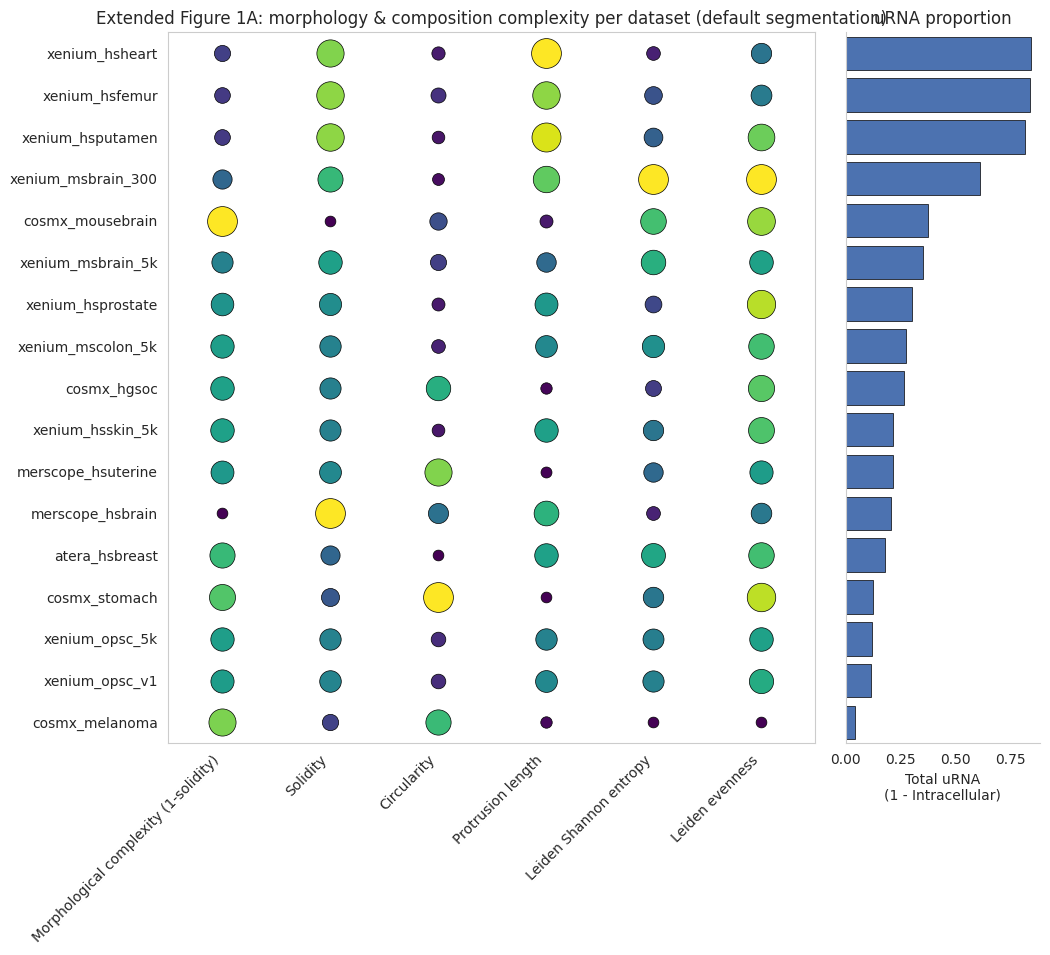

In [7]:
from sklearn.preprocessing import MinMaxScaler

dataset_order = extended_df.xs("rois", level="segmentation").sort_values("total_uRNA").index.tolist()

fig1a_metrics = [
    "morphological_complexity_mean", "solidity_mean", "circularity_mean", "protrusion_length_mean",
    "leiden_shannon", "leiden_evenness",
]
fig1a_labels = [
    "Morphological complexity (1-solidity)", "Solidity", "Circularity", "Protrusion length",
    "Leiden Shannon entropy", "Leiden evenness",
]

fig1a_df = extended_df.xs("rois", level="segmentation").loc[dataset_order]
plot_df = fig1a_df[fig1a_metrics]
scaled = pd.DataFrame(MinMaxScaler().fit_transform(plot_df), index=plot_df.index, columns=plot_df.columns)
bar_values = fig1a_df["total_uRNA"]

fig, (ax, ax_bar) = plt.subplots(
    1, 2, figsize=(1.1 * len(fig1a_metrics) + 4, 0.45 * len(dataset_order) + 2),
    gridspec_kw={"width_ratios": [len(fig1a_metrics), 1.8]}, sharey=True,
)
for i, metric in enumerate(fig1a_metrics):
    for j, sample in enumerate(dataset_order):
        val = scaled.loc[sample, metric]
        if pd.isna(val):
            continue
        ax.scatter(i, j, s=400 * (0.15 + val), c=[val], cmap="viridis", vmin=0, vmax=1, edgecolor="black", linewidth=0.5)
ax.set_xticks(range(len(fig1a_metrics)))
ax.set_xticklabels(fig1a_labels, rotation=45, ha="right")
ax.set_yticks(range(len(dataset_order)))
ax.set_yticklabels(dataset_order)
ax.set_xlim(-0.5, len(fig1a_metrics) - 0.5)
ax.set_ylim(-0.5, len(dataset_order) - 0.5)
ax.grid(False)
ax.set_title("Extended Figure 1A: morphology & composition complexity per dataset (default segmentation)")

ax_bar.barh(range(len(dataset_order)), bar_values.values, color="#4C72B0", edgecolor="black", linewidth=0.5)
ax_bar.set_xlabel("Total uRNA\n(1 - Intracellular)")
ax_bar.set_title("uRNA proportion")
ax_bar.grid(False)
ax_bar.spines["top"].set_visible(False)
ax_bar.spines["right"].set_visible(False)

plt.tight_layout()
plt.savefig(os.path.join(saving_path, "extended_figure1a_dotmatrix.pdf"), format="pdf", bbox_inches="tight")
plt.show()

### 1b. Full metric heatmap — all samples x all characteristics

Complements the dot-matrix above with every metric (morphology, Leiden composition diversity,
and the new tissue-intrinsic spatial-structure metrics) side by side, z-scored per column so
metrics with very different units/scales are visually comparable in one figure.

/tmp/ipykernel_2425025/548229752.py:88: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


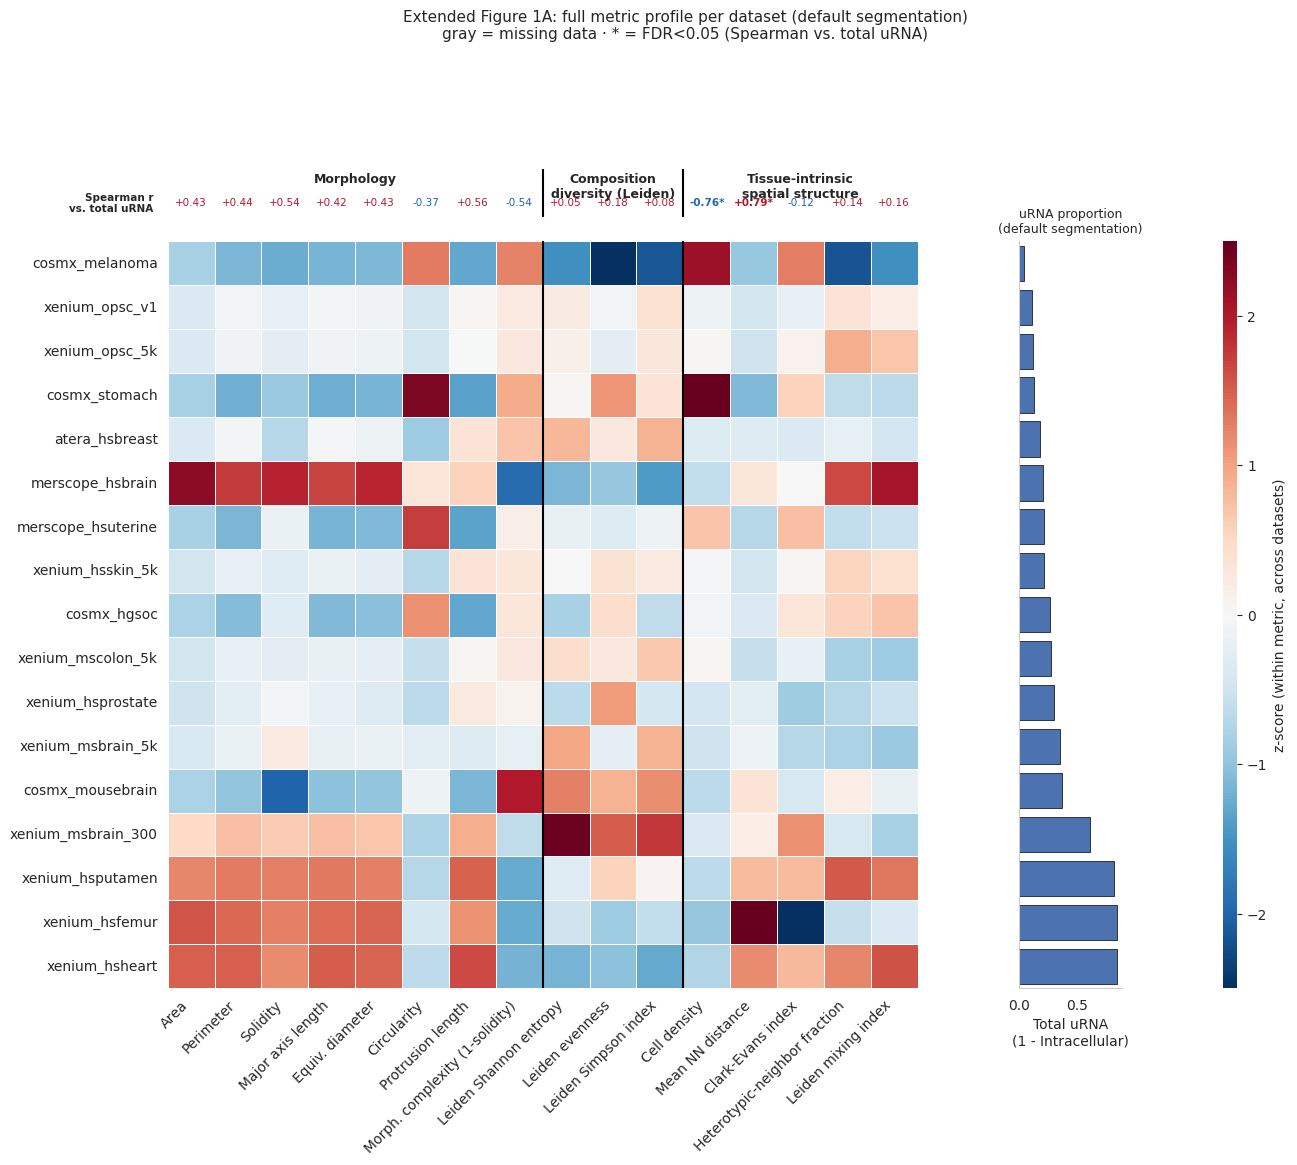

In [8]:
heatmap_metrics = [
    ("area_mean", "Area"), ("perimeter_mean", "Perimeter"), ("solidity_mean", "Solidity"),
    ("major_axis_length_mean", "Major axis length"), ("equivalent_diameter_mean", "Equiv. diameter"),
    ("circularity_mean", "Circularity"), ("protrusion_length_mean", "Protrusion length"),
    ("morphological_complexity_mean", "Morph. complexity (1-solidity)"),
    ("leiden_shannon", "Leiden Shannon entropy"), ("leiden_evenness", "Leiden evenness"),
    ("leiden_simpson", "Leiden Simpson index"),
    ("cell_density", "Cell density"), ("mean_nn_distance", "Mean NN distance"),
    ("clark_evans_index", "Clark-Evans index"),
    ("leiden_heterotypic_neighbor_frac", "Heterotypic-neighbor fraction"),
    ("leiden_mixing_index", "Leiden mixing index"),
]
heatmap_cols = [c for c, _ in heatmap_metrics]
heatmap_labels = [l for _, l in heatmap_metrics]
group_bounds = [0, 8, 11, 16]  # morphology | composition diversity | tissue-intrinsic
group_labels = ["Morphology", "Composition\ndiversity (Leiden)", "Tissue-intrinsic\nspatial structure"]

# dataset_order (defined above, Fig1A panel) is already sorted by total_uRNA (default
# segmentation) -- reused here so both panels of Extended Figure 1A share one consistent
# sample ordering.
heat_df = extended_df.xs("rois", level="segmentation").loc[dataset_order, heatmap_cols]
heat_z = (heat_df - heat_df.mean()) / heat_df.std()  # per-column z-score; NaN-safe, NaN stays NaN
bar_values = extended_df.xs("rois", level="segmentation").loc[dataset_order, "total_uRNA"]

# Per-metric Spearman correlation vs. total_uRNA, default segmentation -- reuses corr_default
# (computed above in the correlation-analysis section) rather than recomputing; heatmap_cols
# is identical (same metrics, same order) to morph_metric_cols used there.
corr_urna = (
    corr_default[corr_default["uRNA_category"] == "total_uRNA"]
    .set_index("metric").reindex(heatmap_cols)
)

fig = plt.figure(figsize=(0.55 * len(heatmap_cols) + 5, 0.42 * len(dataset_order) + 3.5))
gs = fig.add_gridspec(2, 3, height_ratios=[1.1, len(dataset_order)],
                       width_ratios=[len(heatmap_cols), 2.2, 0.3],
                       hspace=0.06, wspace=0.35)
ax = fig.add_subplot(gs[1, 0])
ax_corr = fig.add_subplot(gs[0, 0], sharex=ax)
ax_bar = fig.add_subplot(gs[1, 1], sharey=ax)
cbar_ax = fig.add_subplot(gs[1, 2])

ax.set_facecolor("#dddddd")
sns.heatmap(heat_z, mask=heat_df.isna(), cmap="RdBu_r", center=0, vmin=-2.5, vmax=2.5,
            xticklabels=heatmap_labels, yticklabels=dataset_order,
            cbar_ax=cbar_ax, cbar_kws={"label": "z-score (within metric, across datasets)"},
            linewidths=0.4, linecolor="white", ax=ax)
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
ax.set_ylabel("")
for b in group_bounds[1:-1]:
    ax.axvline(b, color="black", linewidth=1.5)

# Top annotation row: Spearman r of each metric vs. total uRNA (default segmentation).
ax_corr.set_ylim(0, 1)
for i, col in enumerate(heatmap_cols):
    r = corr_urna.loc[col, "spearman_r"]
    p_fdr = corr_urna.loc[col, "p_fdr"]
    sig = bool(pd.notna(p_fdr) and p_fdr < 0.05)
    if pd.isna(r):
        txt, color, weight = "n/a", "gray", "normal"
    else:
        txt = f"{r:+.2f}" + ("*" if sig else "")
        color = "#b2182b" if r > 0 else "#2166ac"
        weight = "bold" if sig else "normal"
    ax_corr.text(i + 0.5, 0.3, txt, ha="center", va="center", fontsize=7.5, color=color, fontweight=weight)
for b in group_bounds[1:-1]:
    ax_corr.axvline(b, color="black", linewidth=1.5)
for start, end, label in zip(group_bounds[:-1], group_bounds[1:], group_labels):
    ax_corr.text((start + end) / 2, 0.92, label, ha="center", va="top", fontsize=9, fontweight="bold")
ax_corr.text(-0.3, 0.3, "Spearman r\nvs. total uRNA", ha="right", va="center", fontsize=7.5, fontweight="bold")
ax_corr.axis("off")

# Reference panel: total uRNA (1 - Intracellular) under default segmentation, same row
# order/alignment as the heatmap (row i center = y=i+0.5, matching seaborn's inverted y-axis).
ax_bar.barh(np.arange(len(dataset_order)) + 0.5, bar_values.values, height=0.8,
            color="#4C72B0", edgecolor="black", linewidth=0.5)
ax_bar.set_xlabel("Total uRNA\n(1 - Intracellular)")
ax_bar.set_title("uRNA proportion\n(default segmentation)", fontsize=9)
ax_bar.grid(False)
ax_bar.spines["top"].set_visible(False)
ax_bar.spines["right"].set_visible(False)
ax_bar.tick_params(left=False, labelleft=False)

fig.suptitle(
    "Extended Figure 1A: full metric profile per dataset (default segmentation)\n"
    "gray = missing data · * = FDR<0.05 (Spearman vs. total uRNA)",
    y=1.03, fontsize=11,
)
plt.tight_layout()
plt.savefig(os.path.join(saving_path, "extended_figure1a_full_heatmap.pdf"), format="pdf", bbox_inches="tight")
plt.show()

### 2. Dataset-level scatterplots — headline: Total uRNA vs. morphology/diversity

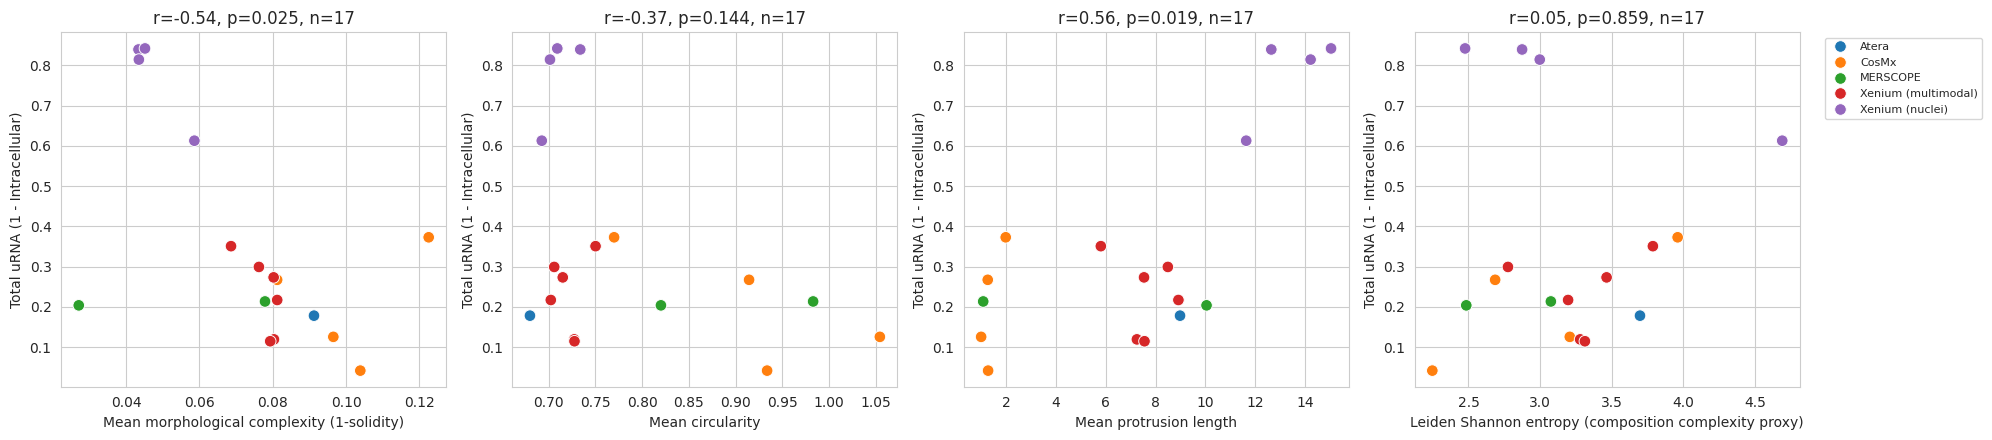

In [9]:
headline_metrics = ["morphological_complexity_mean", "circularity_mean", "protrusion_length_mean", "leiden_shannon"]
headline_labels = {
    "morphological_complexity_mean": "Mean morphological complexity (1-solidity)",
    "circularity_mean": "Mean circularity",
    "protrusion_length_mean": "Mean protrusion length",
    "leiden_shannon": "Leiden Shannon entropy (composition complexity proxy)",
}

tech_order = sorted(default_df["technology_detailed"].dropna().unique())
tech_palette = dict(zip(tech_order, sns.color_palette(n_colors=len(tech_order))))

fig, axes = plt.subplots(1, len(headline_metrics), figsize=(5 * len(headline_metrics), 4.5))
for ax, m in zip(axes, headline_metrics):
    sub = default_df[[m, "total_uRNA", "technology_detailed"]].dropna(subset=[m, "total_uRNA"])
    # Fix hue_order/palette explicitly: seaborn otherwise assigns colors per-panel based on
    # which categories happen to be present in that panel's data, which shifts the same
    # category to a different color across panels when coverage differs (e.g. CosMx has no
    # morphology data, so it silently drops out of some panels and the remaining categories
    # get reassigned colors).
    sns.scatterplot(data=sub, x=m, y="total_uRNA", hue="technology_detailed", hue_order=tech_order,
                     palette=tech_palette, ax=ax, s=70, legend=(ax is axes[-1]))
    if len(sub) >= 4:
        r, p = spearmanr(sub[m], sub["total_uRNA"])
        ax.set_title(f"r={r:.2f}, p={p:.3f}, n={len(sub)}")
    ax.set_xlabel(headline_labels[m])
    ax.set_ylabel("Total uRNA (1 - Intracellular)")
if axes[-1].get_legend() is not None:
    axes[-1].legend(bbox_to_anchor=(1.05, 1), loc="upper left", fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(saving_path, "dataset_scatter_total_urna.pdf"), format="pdf", bbox_inches="tight")
plt.show()

### Supplementary: full metric x category scatter grid

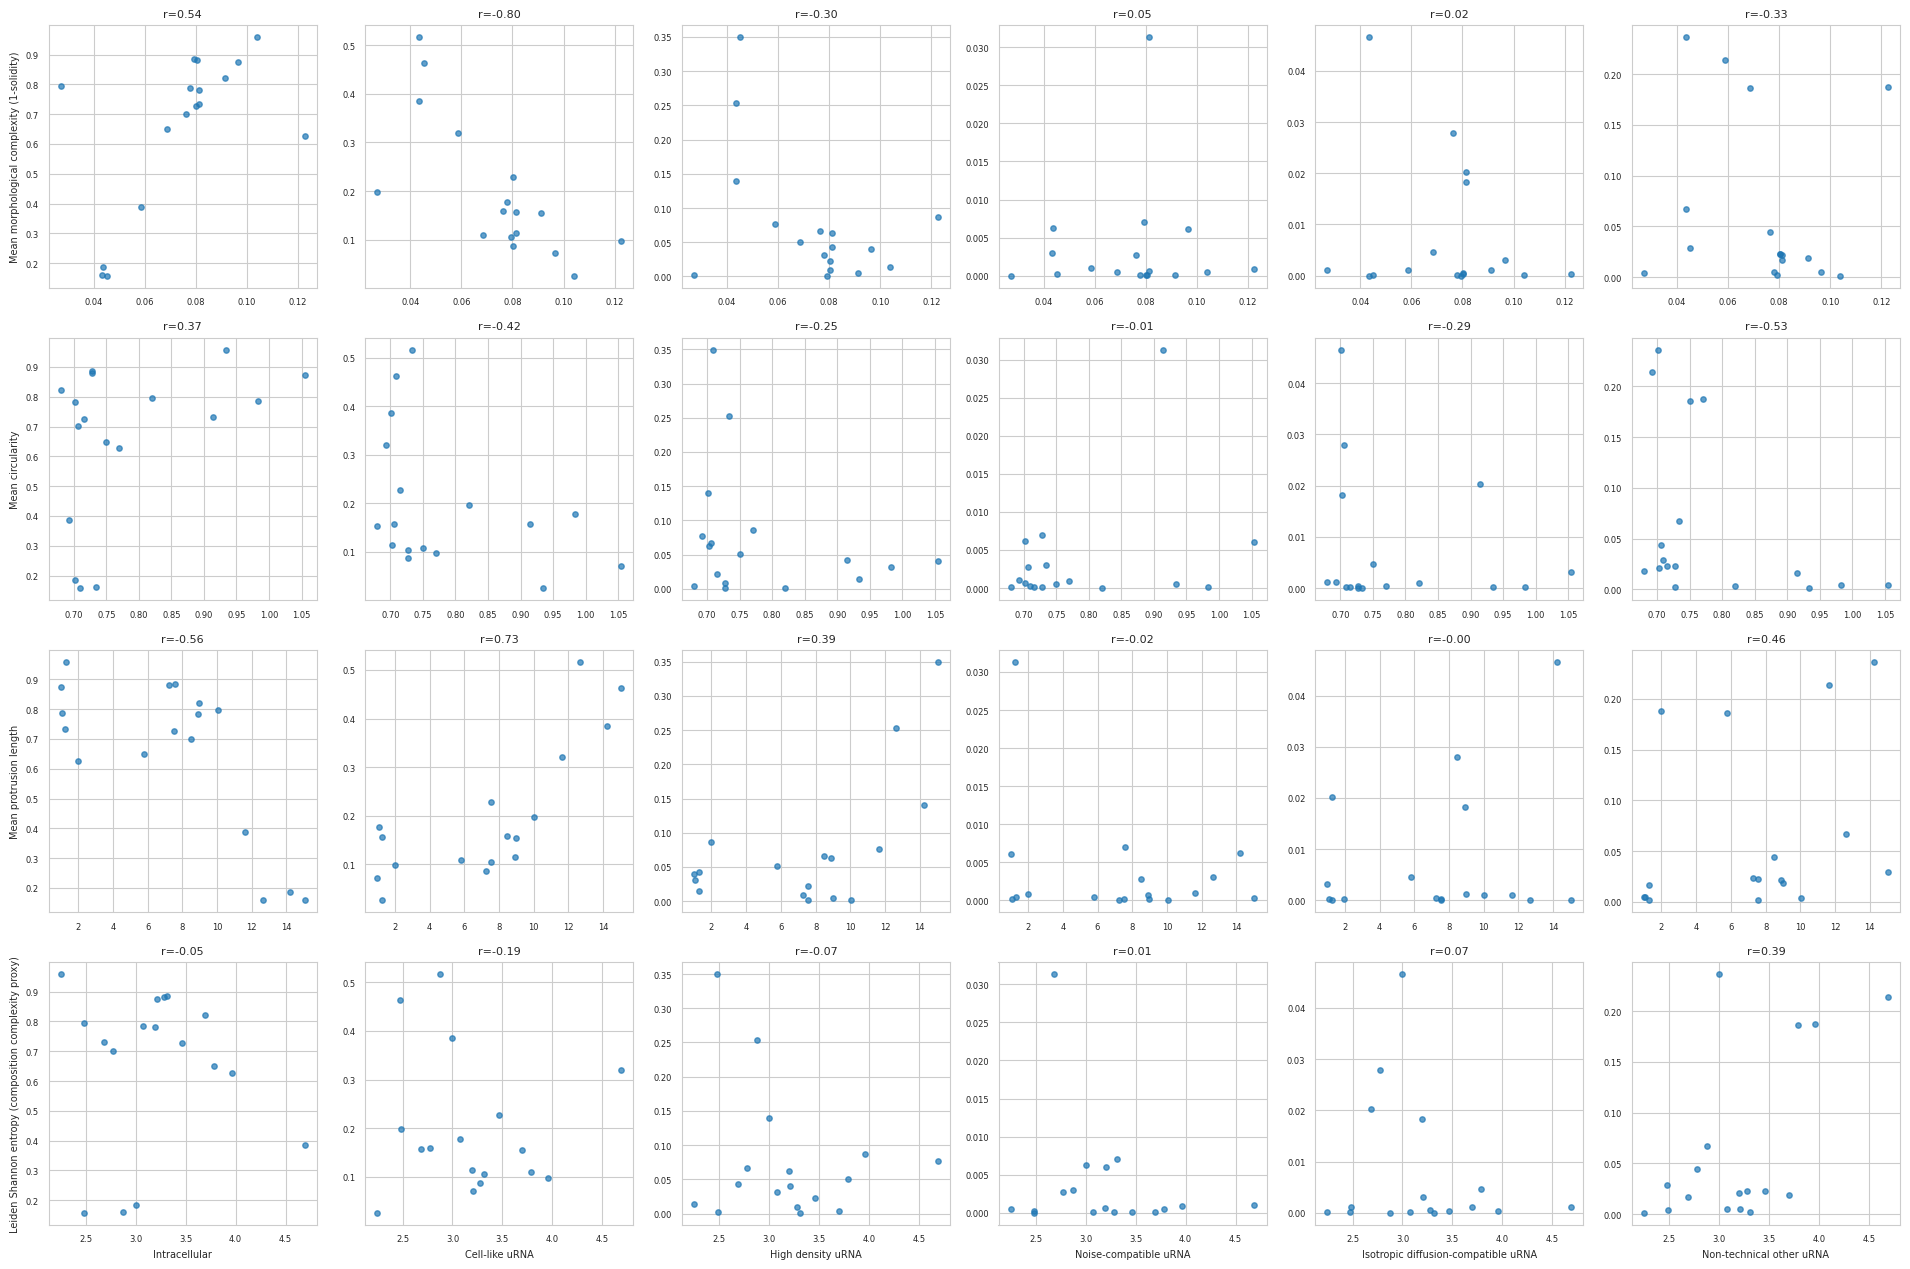

In [10]:
fig, axes = plt.subplots(len(headline_metrics), len(uRNA_categories), figsize=(3.2 * len(uRNA_categories), 3.2 * len(headline_metrics)))
for i, m in enumerate(headline_metrics):
    for j, cat in enumerate(uRNA_categories):
        ax = axes[i, j]
        sub = default_df[[m, cat]].dropna()
        ax.scatter(sub[m], sub[cat], s=15, alpha=0.7)
        if len(sub) >= 4:
            r, p = spearmanr(sub[m], sub[cat])
            ax.set_title(f"r={r:.2f}", fontsize=8)
        if i == len(headline_metrics) - 1:
            ax.set_xlabel(cat, fontsize=7)
        if j == 0:
            ax.set_ylabel(headline_labels[m], fontsize=7)
        ax.tick_params(labelsize=6)
plt.tight_layout()
plt.savefig(os.path.join(saving_path, "dataset_scatter_grid_all_categories.pdf"), format="pdf", bbox_inches="tight")
plt.show()

### 3. Correlation heatmaps (default vs. pooled segmentations)

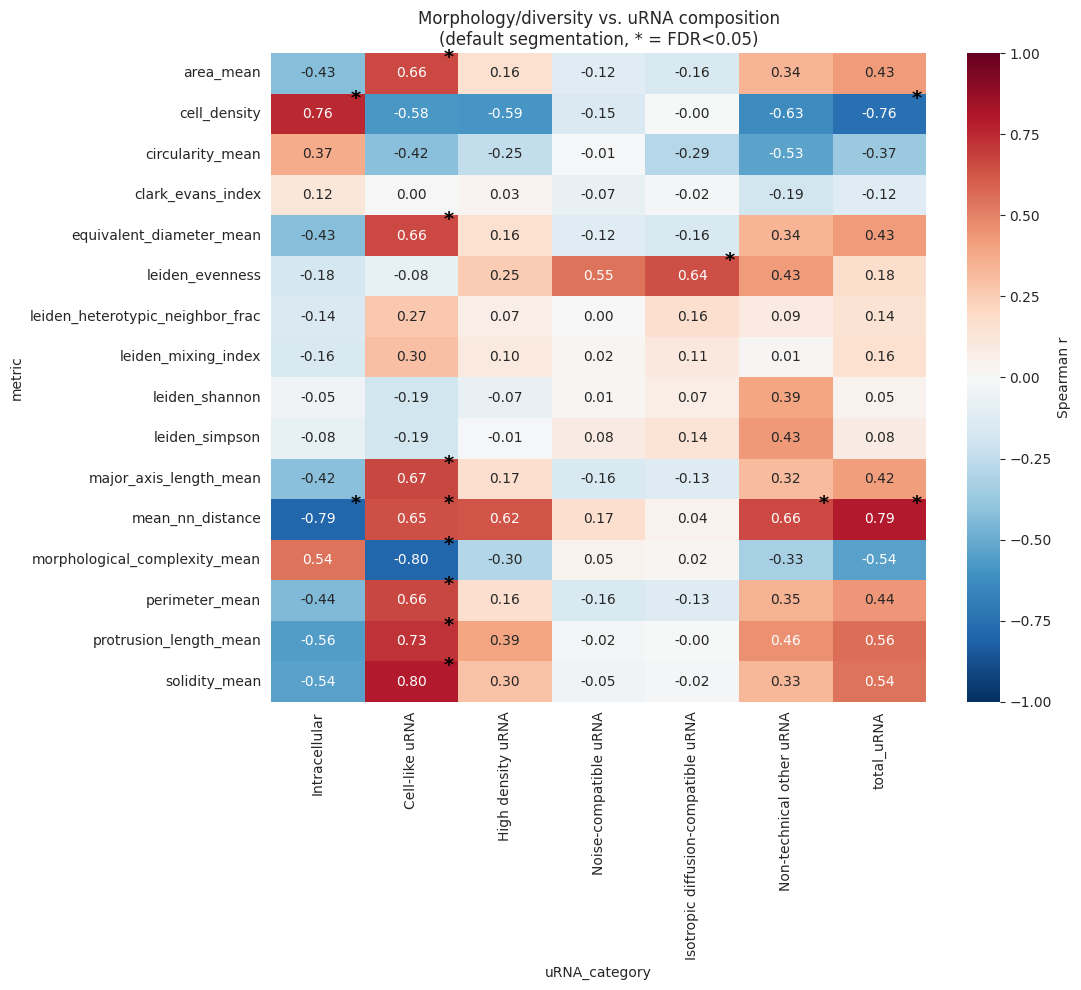

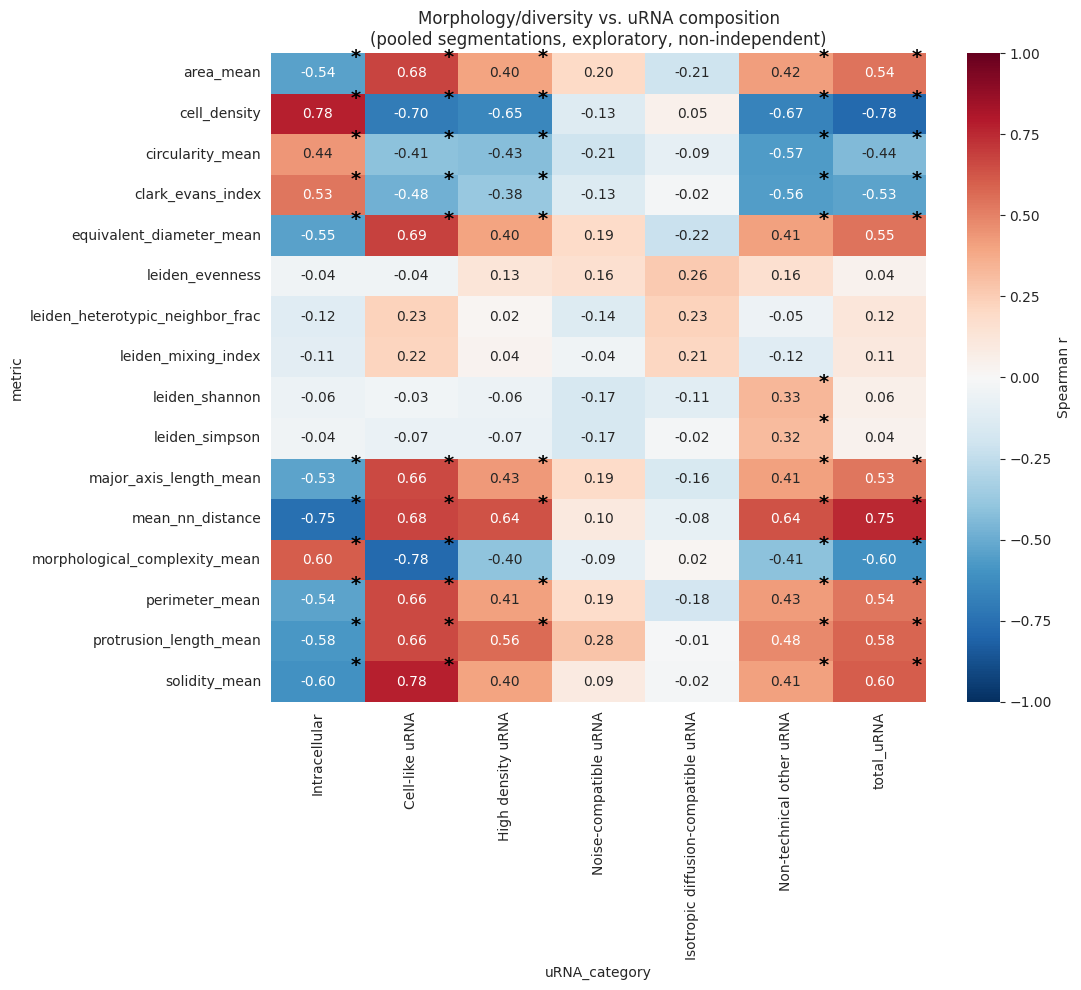

In [11]:
def plot_corr_heatmap(corr_df, title, out_name):
    r_mat = corr_df.pivot(index="metric", columns="uRNA_category", values="spearman_r")
    sig_mat = corr_df.pivot(index="metric", columns="uRNA_category", values="p_fdr") < 0.05
    r_mat = r_mat.reindex(columns=uRNA_categories + ["total_uRNA"])
    sig_mat = sig_mat.reindex(columns=uRNA_categories + ["total_uRNA"])

    fig, ax = plt.subplots(figsize=(1.3 * r_mat.shape[1] + 2, 0.5 * r_mat.shape[0] + 2))
    sns.heatmap(r_mat, cmap="RdBu_r", center=0, vmin=-1, vmax=1, annot=True, fmt=".2f",
                cbar_kws={"label": "Spearman r"}, ax=ax)
    for i, row in enumerate(r_mat.index):
        for j, col in enumerate(r_mat.columns):
            if sig_mat.loc[row, col]:
                ax.text(j + 0.85, i + 0.25, "*", color="black", fontsize=14, fontweight="bold")
    ax.set_title(title)
    plt.tight_layout()
    plt.savefig(os.path.join(saving_path, out_name), format="pdf", bbox_inches="tight")
    plt.show()

plot_corr_heatmap(corr_default, "Morphology/diversity vs. uRNA composition\n(default segmentation, * = FDR<0.05)", "correlation_heatmap_default.pdf")
plot_corr_heatmap(corr_pooled, "Morphology/diversity vs. uRNA composition\n(pooled segmentations, exploratory, non-independent)", "correlation_heatmap_pooled.pdf")

## Summary

- `morphology_diversity_summary.csv`, `extended_figure1a_metadata.csv`,
  `correlation_default_segmentation.csv`, `correlation_pooled_segmentations.csv` saved to
  `figures/morphology_urna_association/`, along with the plots above.
- Coverage/missingness (see table above) should be quoted in the reviewer response.
- Cell-type-resolved analysis (real annotation, not the Leiden proxy) is done separately for
  `xenium_msbrain_5k` in `notebooks/4_detailed_analysis/5_computing_cell_scores_msbrain.ipynb`.